# FRB population DM distribution - MeerKAT coherent beam (CB)

Coherent-beam version of the single-telescope DM-distribution notebook. Differences from the incoherent-beam version:

1. MeerKAT coherent-beam telescope parameters (`meerkat_coherent`).
2. Gain = primary-beam gain (boosted by `n_dishes`, not `sqrt(n_dishes)`) x tied-array (coherent) beam response from `beam_parameters.csv`.
3. FRBs are drawn over the telescope's primary-beam disc (sky area = primary-beam area, as before); any FRB with `theta_frb >= theta_tiling` is not detected.

The last cell saves the weighted DM distribution to `/home/thsu/FRB_population/DM_distribution`.


In [45]:

from pathlib import Path
import time
import numpy as np
from astropy.cosmology import Planck18 as cosmo
import pandas as pd
import matplotlib.pyplot as plt
from scipy.integrate import quad, simps, cumtrapz  # ADD cumtrapz HERE
from scipy.optimize import curve_fit
from scipy.special import erf
import sympy as sp
from scipy.stats import gaussian_kde
import matplotlib.patches as mpatches
from astropy.cosmology import Planck18 as cosmo, z_at_value
from astropy import units as u
from scipy.interpolate import interp1d
from astropy.cosmology import FlatLambdaCDM

In [46]:
# ============================================================================
# TELESCOPE SELECTION
# ============================================================================
TELESCOPE = "Meerkat_coherent"

TELESCOPE_PARAMS = {
    "meerkat_coherent": {
        "D": 13.5,
        "eta": 0.70,
        "Trec": 20,
        "Tsky": 3,
        "BW": 856e6,
        "nu_cen": 1.284e9,
        "n_comp": 16,
        "n_dishes": 40,
        "n_chan": 2048,
        "mode": "coherent",
        "description": "MeerKAT array - coherent beam (phase alignment)",
        "tsamp": 306.24e-6,
        "fov": 0.4,
    },
}


In [47]:
alpha_intrinsic = 0  # Fixed intrinsic spectral index

In [48]:

# # EFFECT CONTROL FLAGS
# # ============================================================================
USE_COSMOLOGY = True      # Tozggle Euclidean vs cosmological universe (affects distances, volumes)
USE_SFR = True           
USE_SMEARING = True      
USE_SPECTRAL_INDEX = True 


# USE_COSMOLOGY = False
# USE_SFR = False           
# USE_SMEARING = False    
# USE_SPECTRAL_INDEX = False

USE_BEAM = True
# USE_BEAM = False

# # # Luminosity function parameters
LUMINOSITY_FUNCTION = "schechter"  
# LUMINOSITY_FUNCTION = "std" 

In [49]:
# Load selected telescope
if TELESCOPE.lower() not in TELESCOPE_PARAMS:
    raise ValueError(f"Telescope must be one of: {list(TELESCOPE_PARAMS.keys())}")

params = TELESCOPE_PARAMS[TELESCOPE.lower()]

# Physical constants
k = 1.38e-23
c = 3.0e8

# Extract telescope parameters
D = params["D"]
eta = params["eta"]
n_dishes = params["n_dishes"]

# Single-dish on-axis gain (K/Jy)
G0_single = np.pi * D*D/4 * eta/2.0/k*1e-26
# Coherent beam: primary-beam gain is boosted by n_dishes (NOT sqrt(n_dishes))
G0 = n_dishes * G0_single

Np = 2


In [50]:
# ============================================================================
# REDSHIFT PARAMETERS
# ============================================================================
dz = 0.001
z_min = 0.01
z_max = 5.0
z_array_opt = np.arange(z_min, z_max, dz)

# Options: "schechter" or "std"


L_STAR = 1e13  # Characteristic luminosity (Jy·kpc²)
ALPHA_SCH = -1.2  # Faint-end slope
L_MIN_SCH = 1e6
L_MAX_SCH = 1e16

# L_std = 2.4e14  # Jy·kpc²
L_std = 1*1e11  # Jy·kpc²

# Simulation parameters
# theta_max = 2*1.22*c/D/nu_min # please note here
fscale = 100 * 1e-7  # FRB rate scaling factor

SNR_threshold = 8
t_obs = 0.001
TARGET_DETECTIONS = 10  # Target 10 detections per z-bin

# Cosmology
cosmo = FlatLambdaCDM(H0=70, Om0=0.3)

np.random.seed(42)


In [51]:
def gaussian_beam_gain(nu, G0, theta, D, c):
    """
    Gaussian beam gain with frequency dependence
    G(ν) = G₀ × exp[−θ²ν²D²×2.355²/(2×1.22²×c²)]
    """
    # Exponent coefficient
    coeff = (theta**2 * D**2 * 2.355**2) / (2 * 1.22**2 * c**2)
    return G0 * np.exp(-coeff * nu**2)

# Pre-calculate constants for speed
_COEFF_CONST = (2.355**2) / (2 * 1.22**2 * (3.0e8**2))

def gaussian_beam_gain_fast(nu_array, G0, theta, D):
    """Optimized version for the inner loop"""
    coeff = theta**2 * D**2 * _COEFF_CONST
    return G0 * np.exp(-coeff * nu_array**2)


def SNR(S,t,G,BW,Np,Trec,Tsky):
    return(S*G*np.sqrt(BW*t*Np)/(Trec+Tsky))

In [52]:
def schechter_function(L, L_star, alpha, phi_star=1.0):
    """
    Schechter luminosity function.
    
    φ(L) = φ* (L/L*)^α * exp(-L/L*)
    
    Parameters:
    -----------
    L : float or array
        Luminosity
    L_star : float
        Characteristic luminosity (knee of the function)
    alpha : float
        Faint-end slope (typically negative)
    phi_star : float
        Normalization constant (default: 1.0)
    
    Returns:
    --------
    phi : float or array
        Number density at luminosity L
    """
    x = L / L_star
    return phi_star * x**alpha * np.exp(-x)

In [53]:
def create_truncated_schechter_sampler(L_min, L_max, L_star, alpha):
    """Create sampler for Schechter function truncated between L_min and L_max"""
    L_grid = np.logspace(np.log10(L_min), np.log10(L_max), 2000)
    phi_grid = schechter_function(L_grid, L_star, alpha)
    
    # REMOVE THIS LINE:
    # from scipy.integrate import cumtrapz
    
    cdf = cumtrapz(phi_grid, L_grid, initial=0)
    cdf = cdf / cdf[-1]
    
    inv_cdf = interp1d(cdf, L_grid, kind='linear', 
                       bounds_error=False, fill_value=(L_min, L_max))
    return inv_cdf

In [54]:

# ============================================================================
# CREATE TRUNCATED SCHECHTER SAMPLER FOR EACH Z
# ============================================================================
print("Creating truncated Schechter samplers...")

def create_truncated_schechter_sampler(L_min, L_max, L_star, alpha):
    """Create sampler for Schechter function truncated between L_min and L_max"""
    L_grid = np.logspace(np.log10(L_min), np.log10(L_max), 2000)
    phi_grid = schechter_function(L_grid, L_star, alpha)
    
    from scipy.integrate import cumtrapz
    cdf = cumtrapz(phi_grid, L_grid, initial=0)
    cdf = cdf / cdf[-1]
    
    inv_cdf = interp1d(cdf, L_grid, kind='linear', 
                       bounds_error=False, fill_value=(L_min, L_max))
    return inv_cdf

sampler_cache = {}
print(f"  Done!\n")

def std_sampler(L_candle):
    """Return a fixed luminosity sampler for standard candle model"""
    def sampler(u):
        return L_candle
    return sampler

Creating truncated Schechter samplers...
  Done!



In [55]:
TEL_KEY = "meerkat_coherent"   # telescope simulated in this notebook


In [56]:
# ============================================================================
# TIED-ARRAY (COHERENT) BEAM SETUP: 3 beams on a hexagonal/triangular tiling
# ============================================================================
beam_params = pd.read_csv('/home/thsu/FRB_population/MeerKat_beams/beam_parameters.csv')
print(beam_params.head())
beam_sep = beam_params['beam_sep'].iloc[0]

# Units of the beam coordinates (beam_sep, sigma_x, sigma_y) in degrees.
# ASSUMPTION: the csv is in degrees. Change this if it is arcmin (1/60) etc.
BEAM_UNIT_DEG = 1/3600   # csv beam_sep / sigma / fwhm are in arcsec

R = beam_sep / np.sqrt(3)
beam_positions = np.array([
    [0, R],                    # Top
    [-beam_sep/2, -R/2],       # Bottom-left
    [beam_sep/2, -R/2]         # Bottom-right
])   # centroid of the triangle = pointing centre = (0, 0)

# Tiling radius: FRBs at theta >= theta_tiling from the pointing centre are not discovered
theta_tiling = np.pi * (0.4668697) / 180   # radian

# --- tied-beam widths as a function of frequency --------------------------------
_sx_raw = beam_params['sigma_x'].values.astype(float)
_sy_raw = beam_params['sigma_y'].values.astype(float)
_freq_col = next((col for col in beam_params.columns
                  if col.lower() in ('freq', 'frequency', 'nu', 'freq_hz', 'freq_mhz', 'nu_hz', 'nu_mhz')), None)

def interp_sigma_to(nu_target):
    """Return (sigma_x, sigma_y) of the tied beams evaluated at frequencies nu_target (Hz)."""
    nu_target = np.atleast_1d(nu_target).astype(float)
    if _freq_col is not None:
        f = beam_params[_freq_col].values.astype(float)
        if f.max() < 1e5:    # looks like MHz
            f = f * 1e6
        order = np.argsort(f)
        return (np.interp(nu_target, f[order], _sx_raw[order]),
                np.interp(nu_target, f[order], _sy_raw[order]))
    # No frequency column: assume the csv rows span the observing band uniformly
    # (lowest -> highest frequency) and resample onto the requested frequencies.
    pos = (nu_target - nu_target.min()) / max(nu_target.max() - nu_target.min(), 1e-30)
    idx = np.linspace(0, 1, len(_sx_raw))
    return np.interp(pos, idx, _sx_raw), np.interp(pos, idx, _sy_raw)

print(f"beam_sep = {beam_sep}, tiling radius = {np.degrees(theta_tiling):.4f} deg, "
            f"frequency column: {_freq_col if _freq_col else 'NONE (rows assumed to span the band uniformly)'}")

def sample_frbs_in_disc(n, theta_lim_rad):
    """Uniform-on-the-sky positions inside a disc of radius theta_lim_rad about the
    pointing centre. Returns (x, y) in the beam-csv units and theta in radian."""
    theta = theta_lim_rad * np.sqrt(np.random.random(n))
    phi = 2 * np.pi * np.random.random(n)
    scale = (180.0 / np.pi) / BEAM_UNIT_DEG          # rad -> csv units
    return theta * np.cos(phi) * scale, theta * np.sin(phi) * scale, theta

def get_beam_response_batch(x, y, beam_pos, sig_x_arr, sig_y_arr):
    """Tied-beam response for n FRBs at all frequencies -> shape (n, n_nu).
    Beams sit on the triangular lattice generated by the 3 vertices in beam_pos;
    response = max over the lattice points nearest to each FRB."""
    s = beam_sep
    a2x, a2y = s / 2.0, s * np.sqrt(3.0) / 2.0
    P0x, P0y = beam_pos[1]                      # bottom-left vertex = lattice origin

    dx, dy = x - P0x, y - P0y
    j0 = dy / a2y                               # fractional lattice coordinates
    i0 = (dx - j0 * a2x) / s
    i_c, j_c = np.round(i0).astype(int), np.round(j0).astype(int)

    resp = np.zeros((len(x), len(sig_x_arr)))
    for di in (-1, 0, 1):                       # 9 neighbouring lattice points
        for dj in (-1, 0, 1):
            i, j = i_c + di, j_c + dj
            bx = P0x + i * s + j * a2x
            by = P0y + j * a2y
            r = np.exp(-0.5 * (((x - bx)[:, None] / sig_x_arr[None, :]) ** 2
                               + ((y - by)[:, None] / sig_y_arr[None, :]) ** 2))
            resp = np.maximum(resp, r)
    return resp

# ---- Frequency-dependent sky temperature (K), from the same csv as the gain frequencies ----
_tsky_col = next((col for col in beam_params.columns if str(col).lower().replace("_", "").strip() == "tsky"), None)
_has_tsky = _tsky_col is not None
tsky_raw = beam_params[_tsky_col].values.astype(float) if _has_tsky else None
if _has_tsky and not np.all(np.isfinite(tsky_raw)):
    raise ValueError("Tsky column in beam_parameters.csv contains NaN/inf")
_tsky_freq_col = _freq_col if _freq_col is not None else (next((col for col in beam_params.columns if col != _tsky_col
                      and (str(col).lower().strip().startswith(("freq", "nu")) or "hz" in str(col).lower())), None))
if _has_tsky and _tsky_freq_col is not None:
    _f = beam_params[_tsky_freq_col].values.astype(float)
    tsky_freqs_Hz = _f * 1e6 if _f.max() < 1e5 else _f
else:
    tsky_freqs_Hz = None

def resample_tsky(nu_target):
    """Tsky (K) at frequencies nu_target (Hz).
    - csv has a frequency column -> interpolate on it;
    - same number of rows as nu_target -> use directly;
    - otherwise rows are assumed to span the band uniformly and are resampled.
    Falls back to the fixed TELESCOPE_PARAMS Tsky if the csv has no 'Tsky' column."""
    nu_target = np.atleast_1d(nu_target).astype(float)
    if not _has_tsky:
        return np.full(nu_target.shape, float(TELESCOPE_PARAMS[TEL_KEY]["Tsky"]))
    if tsky_freqs_Hz is not None:
        o = np.argsort(tsky_freqs_Hz)
        return np.interp(nu_target, tsky_freqs_Hz[o], tsky_raw[o])
    if len(nu_target) == len(tsky_raw):
        return tsky_raw.copy()
    pos = (nu_target - nu_target.min()) / max(nu_target.max() - nu_target.min(), 1e-30)
    return np.interp(pos, np.linspace(0, 1, len(tsky_raw)), tsky_raw)

print(f"Tsky column: {_tsky_col or 'NOT FOUND (using fixed Tsky)'}"
      + (f", {tsky_raw.min():.2f}-{tsky_raw.max():.2f} K ({len(tsky_raw)} rows), "
         f"frequency column: {_tsky_freq_col or 'none'}" if _has_tsky else ""))


   freq_MHz    sigma_x    sigma_y  sigma_avg     fwhm_x     fwhm_y   fwhm_avg  \
0    882.75  33.190537  33.125107  33.157822  78.163714  78.009627  78.086670   
1    936.25  31.331947  31.180012  31.255979  73.786734  73.428929  73.607832   
2    989.75  29.698368  29.442623  29.570495  69.939656  69.337376  69.638516   
3   1043.25  28.247394  27.879667  28.063531  66.522614  65.656616  66.089615   
4   1096.75  26.944176  26.465976  26.705076  63.453536  62.327375  62.890455   

    beam_sep      Tsky  
0  79.063947  5.926634  
1  79.063947  5.468910  
2  79.063947  5.096412  
3  79.063947  4.789864  
4  79.063947  4.535050  
beam_sep = 79.06394719402907, tiling radius = 0.4669 deg, frequency column: freq_MHz
Tsky column: Tsky, 3.30-5.93 K (16 rows), frequency column: freq_MHz


In [57]:


print("\n" + "="*100)
print("RUNNING SINGLE-TELESCOPE RUN (MeerKAT coherent beam)")
print("="*100 + "\n")

all_results = {}
fluence_dm_results = {}
population_totals = {}

colors_tel = {"meerkat_coherent": "#d62728"}
labels_tel = {"meerkat_coherent": "MeerKAT CB"}

H0_km_s_Mpc = cosmo.H0.value if hasattr(cosmo, "H0") else 70.0
DH_Mpc = 299792.458 / H0_km_s_Mpc

# Schechter CDF interpolator -- built ONCE
_L_grid_full = np.logspace(np.log10(L_MIN_SCH), np.log10(L_MAX_SCH), 5000)
_phi_grid_full = schechter_function(_L_grid_full, L_STAR, ALPHA_SCH)
_cdf_full = cumtrapz(_phi_grid_full, _L_grid_full, initial=0)
_cdf_full /= _cdf_full[-1]
_cdf_interp = interp1d(_L_grid_full, _cdf_full, kind="linear",
                       bounds_error=False, fill_value=(0.0, 1.0))

def n_ratio_for(L_min_z):
    if LUMINOSITY_FUNCTION.lower() == "std":
        return 1.0 if L_std >= L_min_z else 0.0
    return 1.0 - _cdf_interp(L_min_z)

BATCH_SIZE = 4096

for tel_key in [TEL_KEY]:
    print(f"\n{'='*60}\nTELESCOPE: {labels_tel[tel_key]}\n{'='*60}")

    params = TELESCOPE_PARAMS[tel_key]
    D = params["D"]
    n_dishes = params["n_dishes"]

    np.random.seed(42)

    L_min_by_z_new = {}
    nu0 = params["nu_cen"]
    nu_cen = params["nu_cen"]
    Trec = params["Trec"]
    Tsky_const = params["Tsky"]   # fixed value, only used if the csv has no Tsky column
    BW = params["BW"]
    n_comp = params["n_comp"]
    BW_comp = BW / n_comp
    nu_min = nu0 - BW / 2
    nu_max = nu0 + BW / 2
    n_chan = params["n_chan"]
    BW_chan = BW / n_chan
    nu_array = np.linspace(nu_min, nu_max, n_comp)
    print (nu_array)
    # Frequency-dependent Tsky (K) at the simulated frequencies, from beam_parameters.csv
    Tsky_nu = resample_tsky(nu_array)                       # (len(nu_array),)
    Tsky_0 = float(resample_tsky(np.array([nu0]))[0])       # at nu0
    if tsky_freqs_Hz is not None:
        if len(tsky_freqs_Hz) == len(nu_array):
            print(f"  Tsky csv vs nu_array: {len(nu_array)} points, max |dnu| = "
                  f"{np.abs(np.sort(tsky_freqs_Hz) - np.sort(nu_array)).max()/1e6:.3f} MHz")
        else:
            print(f"  WARNING: Tsky csv has {len(tsky_freqs_Hz)} frequencies but nu_array has {len(nu_array)}; interpolating")
    freq_powers_scatter = (nu_array / 1e9) ** (-4)

    # Sky area = telescope primary-beam disc (radius 2 x FWHM at nu_min), as in the IB version
    theta_max = 2 * 1.22 * c / D / nu_min
    radius_IB = 1.22 * c / D / nu_min/2
  
    fwhm_deg = 1.22 * (c / nu_min) / D * (180 / np.pi)
    print(fwhm_deg)
    area_tel = np.pi * (2.0 * fwhm_deg) ** 2
    APPLY_TILING_CUT = True      # False -> sample the whole primary-beam disc (no cut)
    theta_draw = min(theta_tiling, theta_max) if APPLY_TILING_CUT else theta_max
    f_tiling = (theta_draw / theta_max) ** 2     # = 1 when there is no cut          # fraction of the telescope disc that is tiled
    print (theta_max, theta_tiling, theta_draw, f_tiling)
    # Coherent gain: n_dishes x single-dish gain (primary-beam part)
    G0_single = np.pi * D * D / 4 * params["eta"] / 2.0 / k * 1e-26
    G0 = n_dishes * G0_single
    G0_max = G0   # best case: on a tied-beam centre, on the primary-beam axis
    G0_desc = f"{G0:.4e} K/Jy ({n_dishes} x {G0_single:.4e})"

    # Tied-beam widths at the simulated frequencies (and at nu0 for the gain ratio)
    sig_x_nu, sig_y_nu = interp_sigma_to(nu_array)
    sig_x_0, sig_y_0 = interp_sigma_to(np.array([nu0]))

    print(f"  Diameter: {D} m, G0: {G0_desc}, theta_tiling: {np.degrees(theta_tiling):.4f} deg, "
          f"theta_max: {np.degrees(theta_max):.3f} deg, tiled fraction of disc: {f_tiling:.4f}")
    print(f"  tied-beam sigma_x: {sig_x_nu.min():.4g}-{sig_x_nu.max():.4g}, sigma_y: {sig_y_nu.min():.4g}-{sig_y_nu.max():.4g} (csv units)")
    if not (np.all(np.isfinite(sig_x_nu)) and np.all(np.isfinite(sig_y_nu))):
        print("  WARNING: non-finite tied-beam sigma -> no FRB can be detected; check beam_parameters.csv")
    print(f"  n_comp: {n_comp}, nu_array: {nu_array[0]/1e6:.0f}-{nu_array[-1]/1e6:.0f} MHz ({len(nu_array)} points)")
    print(f"  Sky area (primary-beam disc): {area_tel:.4f} deg\u00b2")
    print(f"  Trec: {Trec} K, Tsky: {Tsky_nu.min():.1f}-{Tsky_nu.max():.1f} K ({Tsky_0:.1f} K at nu0), BW: {BW/1e6:.0f} MHz, nu_cen: {nu_cen/1e9:.3f} GHz")

    for z in z_array_opt:
        dl = (cosmo.luminosity_distance(z).value * 1000.0) if USE_COSMOLOGY else (DH_Mpc * z * 1000.0)
        G_max = gaussian_beam_gain(nu0, G0_max, 0, D, 3.0e8)
        S_min = SNR_threshold * (Trec + Tsky_0) / (G_max * np.sqrt(BW * t_obs * Np))
        z_factor = (1 + z) ** (-1 - alpha_intrinsic) if USE_SPECTRAL_INDEX else 1.0
        L_min = S_min * (dl ** 2) * z_factor
        L_min_by_z_new[z] = np.clip(L_min, L_MIN_SCH, L_MAX_SCH)

    sampler_cache.clear()

    results_tel = []
    tel_events = []

    _INNER_COEFF_CONST_new = (D ** 2 * 2.355 ** 2) / (2 * 1.22 ** 2 * c ** 2)
    S_SNR_CONST = np.sqrt(BW_comp * t_obs * Np) / (Trec + Tsky_nu)   # (n_nu,) per-frequency noise
    nu_scaling = (nu_array / nu0) ** alpha_intrinsic if USE_SPECTRAL_INDEX else np.ones_like(nu_array)

    for z_idx, z in enumerate(z_array_opt):
        zmin, zmax = z - 0.5 * dz, z + 0.5 * dz
        L_min_z = L_min_by_z_new[z]

        if LUMINOSITY_FUNCTION.lower() == "std":
            if L_min_z > L_std:
                break
            truncated_sampler = std_sampler(L_std)
        else:
            if L_min_z > 8.952e15:
                break
            if L_min_z not in sampler_cache:
                sampler_cache[L_min_z] = create_truncated_schechter_sampler(
                    L_min_z, L_MAX_SCH, L_STAR, ALPHA_SCH
                )
            truncated_sampler = sampler_cache[L_min_z]

        DM = 1000 * z
        wi_z = 0.001 * (1 + z)
        BW_chan_MHz = BW_chan / 1e6
        nu_cen_GHz = nu_cen / 1e9

        if USE_SMEARING:
            w_DM = 8.3e-6 * DM * BW_chan_MHz / (nu_cen_GHz ** 3)
            # w_scatter_comp = (
            #     1.9e-7 * (DM ** 1.5) * (1 + (DM ** 3) * 3.55e-5) * 3 * freq_powers_scatter * 1e-3
            # )
            # w_scatter = np.sqrt(np.sum(w_scatter_comp ** 2) / len(w_scatter_comp))
            w_scatter = 0
            w_sampling = params["tsamp"] 
        else:
            w_DM = w_scatter = w_sampling = 0.0

        w_obs_factor = np.sqrt(wi_z ** 2 + w_DM ** 2 + w_scatter ** 2 + w_sampling ** 2)

        dl = (cosmo.luminosity_distance(z).value * 1000.0) if USE_COSMOLOGY else (DH_Mpc * z * 1000.0)
        z_factor = (1 + z) ** (-1 - alpha_intrinsic) if USE_SPECTRAL_INDEX else 1.0

        n_generated = 0
        detected = []
        max_iterations = 10000

        while len(detected) < TARGET_DETECTIONS and n_generated < max_iterations:
            n = min(BATCH_SIZE, max_iterations - n_generated)

            # 1. FRB positions inside the tiling circle (beam-csv units), pointing centre = (0, 0).
            #    theta_frb < theta_tiling by construction; the skipped FRBs (theta >= theta_tiling)
            #    are accounted for through f_tiling below.
            frb_x, frb_y, theta_frb = sample_frbs_in_disc(n, theta_draw)

            # 2. Luminosity / flux
            lum_b = np.asarray(truncated_sampler(np.random.uniform(0, 1, n)), dtype=float)
            if LUMINOSITY_FUNCTION.lower() == "std":
                lum_b = np.full(n, L_std, dtype=float)
            S0_b = (lum_b / (dl ** 2 * z_factor)) * (wi_z / w_obs_factor)
            S_nu_b = S0_b[:, None] * nu_scaling[None, :]

            # 3. Gain = n_dishes*G0_single * primary envelope * tied-beam response
            if USE_BEAM:
                primary_envelope = np.exp(-(_INNER_COEFF_CONST_new * theta_frb[:, None] ** 2) * nu_array[None, :] ** 2)
                beam_responses = get_beam_response_batch(frb_x, frb_y, beam_positions, sig_x_nu, sig_y_nu)
                G_nu_b = G0 * primary_envelope * beam_responses
                # gain ratio at nu0, G(theta, x, y; nu0)/G0 <= 1
                prim0 = np.exp(-_INNER_COEFF_CONST_new * theta_frb ** 2 * nu0 ** 2)
                tied0 = get_beam_response_batch(frb_x, frb_y, beam_positions, sig_x_0, sig_y_0)[:, 0]
                gain_ratio_b = prim0 * tied0
            else:
                G_nu_b = G0 * np.ones((n, len(nu_array)))
                gain_ratio_b = np.ones(n)

            # 4. S/N
            snr_spectrum_b = S_nu_b * G_nu_b * S_SNR_CONST
            snr_coherent_b = snr_spectrum_b.sum(axis=1) / np.sqrt(n_comp)

            hits = np.where(snr_coherent_b > SNR_threshold)[0]

            need = TARGET_DETECTIONS - len(detected)
            if len(hits) >= need:
                hits_used = hits[:need]
                n_generated += int(hits_used[-1]) + 1
            else:
                hits_used = hits
                n_generated += n

            for i in hits_used:
                fluence_Jyms = (lum_b[i] / (dl ** 2 * z_factor)) * (wi_z * 1000.0)
                detected.append((lum_b[i], fluence_Jyms, gain_ratio_b[i], snr_coherent_b[i],
                                frb_x[i], frb_y[i]))

        n_detected = len(detected)

        if n_detected == TARGET_DETECTIONS:
            detection_rate = (n_detected / n_generated) * f_tiling   # x area fraction inside the tiling radius
            N_ratio = n_ratio_for(L_min_z)

            if USE_COSMOLOGY:
                dt = (cosmo.age(zmin).value - cosmo.age(zmax).value) * 1e9
                dvol = (
                    cosmo.comoving_volume(zmax).value - cosmo.comoving_volume(zmin).value
                ) * (area_tel / (4.0 * np.pi * ((180.0 / np.pi) ** 2)))
            else:
                r_Mpc = DH_Mpc * z
                dr_Mpc = DH_Mpc * dz
                area_sr = area_tel * (np.pi / 180.0) ** 2
                dvol = (r_Mpc ** 2) * dr_Mpc * area_sr
                dr_m = dr_Mpc * 3.0857e22
                dt = dr_m / c / (3600.0 * 24.0 * 365.0)

            psi = (0.015 * ((1 + z) ** 2.7) / (1 + ((1 + z) / 2.9) ** 5.6)) if USE_SFR else 0.015
            nfrb_sfr = psi * dvol * dt * fscale
            n_total_population = detection_rate * N_ratio * nfrb_sfr

            results_tel.append({"z": z, "DM": DM, "n_total_population": n_total_population})

            weight_per_event = n_total_population / TARGET_DETECTIONS
            for lum, fluence_Jyms, gain_ratio, snr_det, fx, fy in detected:
                tel_events.append({
                    "DM": DM, "z": z, "fluence": fluence_Jyms, "weight": weight_per_event,
                    "lum_true": lum, "gain_ratio": gain_ratio,
                    "fluence_obs": fluence_Jyms * gain_ratio,
                    "lum_inferred": lum * gain_ratio,
                    "snr": snr_det,
                    "x": fx,
                    "y": fy,
                })
            if z_idx % 50 == 0:
                print(f"  z={z:.2f}: Pop {n_total_population:.1f}")

    if len(results_tel) == 0:
        raise RuntimeError("No redshift bin reached TARGET_DETECTIONS. Check the tied-beam sigma values / "
                           "BEAM_UNIT_DEG / frequency column of beam_parameters.csv (see printout above).")
    n_frb_weighted = sum(e["weight"] for e in tel_events)
    print(f"  \u2713 {len(results_tel)} redshift bins, {len(tel_events)} detected-FRB samples "
          f"-> n_frb (weighted) = {n_frb_weighted:.1f}")

    all_results[tel_key] = results_tel
    fluence_dm_results[tel_key] = tel_events
    population_totals[tel_key] = np.array([e["weight"] for e in tel_events])

print(f"\n{'='*100}")
print("DONE")
print(f"{'='*100}\n")



RUNNING SINGLE-TELESCOPE RUN (MeerKAT coherent beam)


TELESCOPE: MeerKAT CB
[8.56000000e+08 9.13066667e+08 9.70133333e+08 1.02720000e+09
 1.08426667e+09 1.14133333e+09 1.19840000e+09 1.25546667e+09
 1.31253333e+09 1.36960000e+09 1.42666667e+09 1.48373333e+09
 1.54080000e+09 1.59786667e+09 1.65493333e+09 1.71200000e+09]
  Tsky csv vs nu_array: 16 points, max |dnu| = 26.750 MHz
1.814663837122545
0.06334371754932502 0.00814841344279817 0.00814841344279817 0.01654775252786849
  Diameter: 13.5 m, G0: 1.4521e+00 K/Jy (40 x 3.6303e-02), theta_tiling: 0.4669 deg, theta_max: 3.629 deg, tiled fraction of disc: 0.0165
  tied-beam sigma_x: 17.56-33.19, sigma_y: 17.21-33.13 (csv units)
  n_comp: 16, nu_array: 856-1712 MHz (16 points)
  Sky area (primary-beam disc): 41.3811 deg²
  Trec: 20 K, Tsky: 3.3-5.9 K (3.9 K at nu0), BW: 856 MHz, nu_cen: 1.284 GHz
  z=0.01: Pop 0.7
  z=0.06: Pop 12.6
  z=0.11: Pop 32.2
  z=0.16: Pop 33.6
  z=0.21: Pop 69.2
  z=0.26: Pop 72.1
  z=0.31: Pop 87.1
  z=0.36: Pop

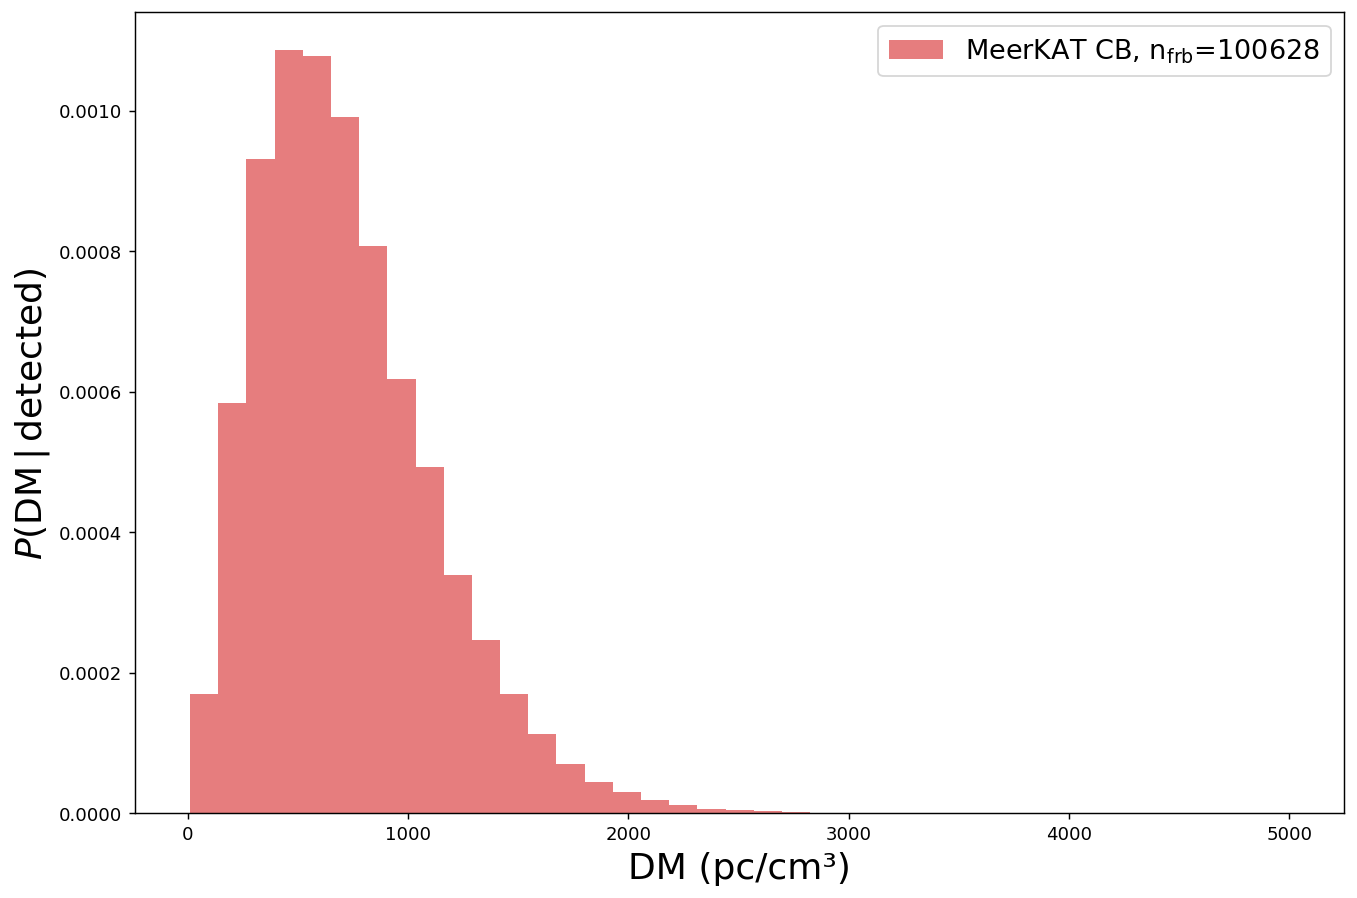

In [58]:
# ----------------------------------------------------------------------------
# DM histogram (weighted population) for this telescope
# ----------------------------------------------------------------------------
%matplotlib inline
results = all_results[TEL_KEY]
DMs  = np.array([r["DM"] for r in results])
pops = np.array([r["n_total_population"] for r in results])
nfrb = pops.sum()

fig, ax = plt.subplots(figsize=(12, 8), dpi=130)
bins = np.linspace(DMs.min(), DMs.max(), 40)
ax.hist(DMs, bins=bins, weights=pops, density=True, alpha=0.6, color=colors_tel[TEL_KEY],
        label=f'{labels_tel[TEL_KEY]}, n$_{{\\mathrm{{frb}}}}$={int(nfrb)}')
ax.set_xlabel("DM (pc/cm\u00b3)", fontsize=20)
ax.set_ylabel(r"$P(\mathrm{DM}\,|\,\mathrm{detected})$", fontsize=20)
ax.legend(fontsize=15)
plt.show()


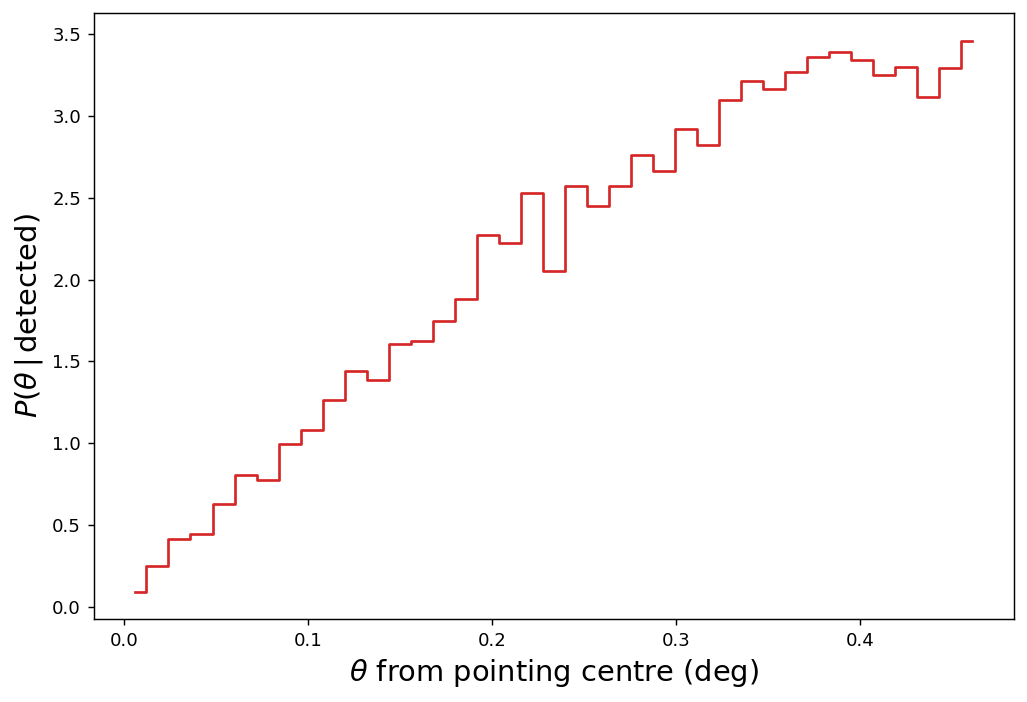

weighted median theta = 0.313 deg, 90% within 0.437 deg


In [59]:
ev = fluence_dm_results[TEL_KEY]
x = np.array([e["x"] for e in ev])
y = np.array([e["y"] for e in ev])
w = np.array([e["weight"] for e in ev])

# offset from pointing centre, in degrees
theta = np.hypot(x, y) * BEAM_UNIT_DEG

theta_hi = np.degrees(theta_draw)                # tiling circle, 0.312 deg
bins = np.linspace(0, theta_hi, 40)

fig, ax = plt.subplots(figsize=(8, 5.5), dpi=130)
h, edges = np.histogram(theta, bins=bins, weights=w, density=True)
mid = 0.5 * (edges[1:] + edges[:-1])
ax.step(mid, h, where="mid", color=colors_tel[TEL_KEY])
ax.set_xlabel(r"$\theta$ from pointing centre (deg)", fontsize=16)
ax.set_ylabel(r"$P(\theta\,|\,\mathrm{detected})$", fontsize=16)
ax.set_xlim()
plt.tight_layout()
plt.show()

order = np.argsort(theta)
cdf = np.cumsum(w[order]) / w.sum()
print(f"weighted median theta = {np.interp(0.5, cdf, theta[order]):.3f} deg, "
      f"90% within {np.interp(0.9, cdf, theta[order]):.3f} deg")

In [60]:
ev = fluence_dm_results[TEL_KEY]
x = np.array([e["x"] for e in ev]); y = np.array([e["y"] for e in ev])
w = np.array([e["weight"] for e in ev])

# (a) inside the half-power contour of any tied beam at nu0
resp0 = get_beam_response_batch(x, y, beam_positions, sig_x_0, sig_y_0)[:, 0]
in_hp = resp0 >= 0.5

# (b) inside the triangle formed by the three beam centres
def in_triangle(px, py, v):
    (x1,y1),(x2,y2),(x3,y3) = v
    d = (y2-y3)*(x1-x3) + (x3-x2)*(y1-y3)
    a = ((y2-y3)*(px-x3) + (x3-x2)*(py-y3)) / d
    b = ((y3-y1)*(px-x3) + (x1-x3)*(py-y3)) / d
    return (a >= 0) & (b >= 0) & (a + b <= 1)
in_tri = in_triangle(x, y, beam_positions)

for name, m in [("half-power (any beam)", in_hp), ("triangle", in_tri)]:
    print(f"{name}: {100*w[m].sum()/w.sum():.2f}")

half-power (any beam): 61.41
triangle: 0.06


In [61]:
# ----------------------------------------------------------------------------
# SAVE: DM distribution of the weighted population -> .npy
#
# Array shape (N, 2), one row per redshift bin that had detections:
#   column 0 = DM (pc/cm^3)          (= 1000 * z)
#   column 1 = n_total_population    (weighted number of FRBs in that bin)
# Weighted DM histogram: np.histogram(arr[:,0], bins=..., weights=arr[:,1]).
# ----------------------------------------------------------------------------
import os
OUT_DIR = "/home/thsu/FRB_population/DM_distribution"
os.makedirs(OUT_DIR, exist_ok=True)

dm_distribution = np.column_stack([DMs, pops])
out_path = os.path.join(OUT_DIR, "DM_distribution_meerkat_cb.npy")
np.save(out_path, dm_distribution)
print(f"Saved {dm_distribution.shape} array (DM, weighted population) -> {out_path}")
print(f"Total weighted population: {pops.sum():.1f}")


Saved (4844, 2) array (DM, weighted population) -> /home/thsu/FRB_population/DM_distribution/DM_distribution_meerkat_cb.npy
Total weighted population: 100628.1
